In [4]:
import os
os.chdir("/Users/nethkurukulasuriya/Downloads/NK_AW_AJ")

In [5]:
import glob
import numpy as np
import matplotlib.pyplot as plt



def get_A614(filename):
    data = np.loadtxt(filename, skiprows=14)   # first 14 lines are the header
    wavelength = data[:, 0]
    absorbance = data[:, 1]
    # average 612-616 nm to cut down noise
    A614 = np.mean(absorbance[(wavelength >= 612) & (wavelength <= 616)])
    # baseline: MB does not absorb at 780-820 nm, so subtract that
    baseline = np.mean(absorbance[(wavelength >= 780) & (wavelength <= 820)])
    return A614 - baseline



def r_squared(x, y, m, b):
    residuals = y - (m * x + b)
    return 1 - np.sum(residuals**2) / np.sum((y - np.mean(y))**2)


Calibration line: slope = 0.04411 per uM, intercept = -0.0173
R^2 = 0.9973
epsilon_614 = 44112 M^-1 cm^-1


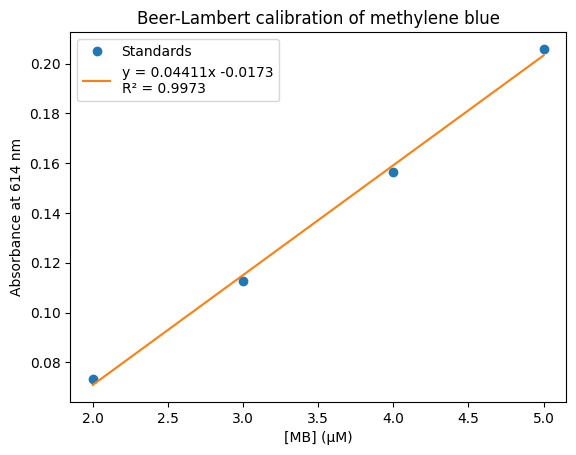

In [6]:
conc = np.array([2, 3, 4, 5])   # uM
cal_files = ["2 uM_Absorbance__0__14-10-01-187.txt",
             "3 uM_Absorbance__0__14-17-23-175.txt",
             "4 uM_Absorbance__0__14-21-24-180.txt",
             "5 uM_Absorbance__0__14-25-00-178.txt"]

A_cal = []
for f in cal_files:
    A_cal.append(get_A614(f))
A_cal = np.array(A_cal)

slope, intercept = np.polyfit(conc, A_cal, 1)   # slope in 1/uM
R2_cal = r_squared(conc, A_cal, slope, intercept)
epsilon = slope * 1e6 / 1.0                     # M^-1 cm^-1  (path length = 1 cm)

print("Calibration line: slope =", round(slope, 5), "per uM, intercept =", round(intercept, 4))
print("R^2 =", round(R2_cal, 4))
print("epsilon_614 =", round(epsilon), "M^-1 cm^-1")

plt.figure()
plt.plot(conc, A_cal, "o", label="Standards")
plt.plot(conc, slope * conc + intercept, "-",
         label=f"y = {slope:.5f}x {intercept:+.4f}\nR² = {R2_cal:.4f}")
plt.xlabel("[MB] (µM)")
plt.ylabel("Absorbance at 614 nm")
plt.title("Beer-Lambert calibration of methylene blue")
plt.legend()
plt.savefig("Fig1_calibration.png", dpi=300)



1 mW : slope = -0.239 uM/s, R^2 = 0.9996 , I0 = 5.506e-09 einstein/s, quantum yield = 0.130
2.5 mW : slope = -0.528 uM/s, R^2 = 0.9992 , I0 = 1.377e-08 einstein/s, quantum yield = 0.115
5 mW : slope = -1.132 uM/s, R^2 = 0.9999 , I0 = 2.753e-08 einstein/s, quantum yield = 0.124


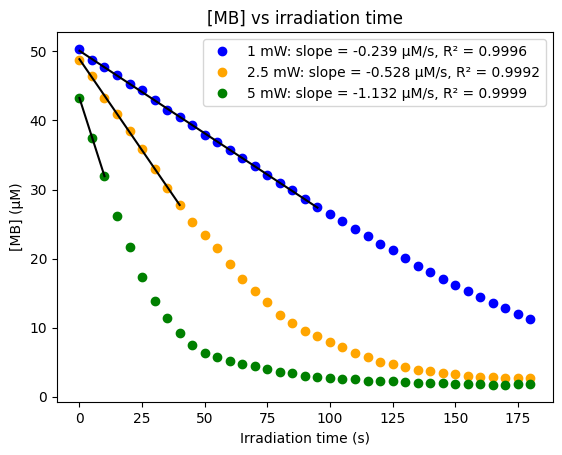

In [ ]:
runs = ["1 mW", "2.5 mW", "5 mW"]
power_mW = [1.0, 2.5, 5.0]
colors = ["blue", "orange", "green"]


n_fit = [20, 9, 3]


h = 6.626e-34          
c = 2.998e8          
NA = 6.022e23 
laser_wl = 658.7e-9 
V = 3.00e-3
f_abs = 0.998 

plt.figure()
print()
for i in range(3):
    time = []
    MB = []
    for k in range(37):
        f = glob.glob("Kinetics/" + runs[i] + "/*_Absorbance__" + str(k) + "__*.txt")[0]
        A = get_A614(f)
        time.append(k * 5)
        MB.append((A - intercept) / slope)
    time = np.array(time)
    MB = np.array(MB)

    n = n_fit[i]
    m, b = np.polyfit(time[:n], MB[:n], 1)
    R2 = r_squared(time[:n], MB[:n], m, b)

    I0 = power_mW[i] * 1e-3 * laser_wl / (h * c * NA)
    rate = -m * 1e-6 * V   
    phi = rate / (I0 * f_abs)

    print(runs[i], ": slope =", round(m, 3), "uM/s, R^2 =", round(R2, 4),
          ", I0 =", "%.3e" % I0, "einstein/s, quantum yield =", "%.3f" % phi)

    plt.plot(time, MB, "o", color=colors[i],
             label=f"{runs[i]}: slope = {m:.3f} µM/s, R² = {R2:.4f}")
    plt.plot(time[:n], m * time[:n] + b, "-", color="black")

plt.xlabel("Irradiation time (s)")
plt.ylabel("[MB] (µM)")
plt.title("[MB] vs irradiation time")
plt.legend()

plt.show()